In [106]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from astropy.io import fits
from astropy.table import Table
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec
from scipy.signal import resample
import h5py
import emcee
import corner

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [107]:
def weighted_reduced_chi_squared(y_obs, y_err_low, y_err_high, y_model, n_params,
                                  x_obs=None, x_err_low=None, x_err_high=None,
                                  gradient=None):
    """
    Calculate the reduced chi-squared for data with asymmetric uncertainties,
    optionally including x uncertainties projected onto y via the model gradient.

    Parameters
    ----------
    y_obs : array_like
        Observed y values.
    y_err_low : array_like
        Lower (negative) uncertainties on y.
    y_err_high : array_like
        Upper (positive) uncertainties on y.
    y_model : array_like
        Model predictions.
    n_params : int
        Number of fitted parameters.
    x_obs : array_like, optional
        Observed x values. Required if x_err_low/x_err_high are given.
    x_err_low : array_like, optional
        Lower (negative) uncertainties on x. If None, treated as zero.
    x_err_high : array_like, optional
        Upper (positive) uncertainties on x. If None, treated as zero.
    gradient : float, optional
        Local gradient of the model (dy/dx), used to project x uncertainty
        onto y. Required if x uncertainties are non-zero.

    Returns
    -------
    chi2_red : float
        Reduced chi-squared.
    """

    y_obs = np.asarray(y_obs, dtype=float)
    y_model = np.asarray(y_model, dtype=float)
    y_err_low = np.asarray(y_err_low, dtype=float)
    y_err_high = np.asarray(y_err_high, dtype=float)

    # Use the appropriate uncertainty depending on which side of the data
    sigma_y = np.where(y_model > y_obs, y_err_high, y_err_low)

    # Handle x uncertainties, if provided
    if x_err_low is None:
        x_err_low = np.zeros_like(y_obs)
    else:
        x_err_low = np.asarray(x_err_low, dtype=float)

    if x_err_high is None:
        x_err_high = np.zeros_like(y_obs)
    else:
        x_err_high = np.asarray(x_err_high, dtype=float)

    # If x errors are all zero, skip the x-error projection entirely —
    # this avoids requiring x_obs/gradient when there's nothing to project
    if np.all(x_err_low == 0) and np.all(x_err_high == 0):
        sigma = sigma_y
    else:
        if x_obs is None or gradient is None:
            raise ValueError("x_obs and gradient must be provided when x uncertainties are non-zero.")

        x_obs = np.asarray(x_obs, dtype=float)
        sigma_x = np.where(y_model > y_obs, x_err_high, x_err_low)

        # project x uncertainty onto y using the model gradient, combine in quadrature
        sigma = np.sqrt(sigma_y**2 + (gradient * sigma_x)**2)

    chi2 = np.sum(((y_obs - y_model) / sigma) ** 2)

    dof = len(y_obs) - n_params
    if dof <= 0:
        raise ValueError("Degrees of freedom must be positive.")

    chi2_red = chi2 / dof

    return chi2_red

In [108]:
def lorentzian_function(x, sigma, mu, amp):
    """
    1D Lorentzian for a histogram density plot. The amplitude is dependent on sigma.
    """

    y = (amp / np.pi) * (0.5 * sigma) / ((x - mu)**2 + (0.5 * sigma)**2)

    return y

In [ ]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_lorentzian_mcmc(corner_path, posterior_sum, x_in, y_in, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # xe_lo = np.zeros(n)
    # xe_hi = np.zeros(n)
    # ye_lo = np.zeros(n)
    # ye_hi = np.zeros(n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    #print(xe_lo)
    #print(xe_hi)
    #print(ye_lo)
    #print(ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    try:
        popt, pcov = curve_fit(lorentzian_function, x - xp, y, p0=[np.std(x-xp), np.mean(x-xp), np.max(y)])
        guess_sig, guess_mu, guess_amp = popt
        print(f"Guesses: sig = {guess_sig:.3f}, mean = {guess_mu:.3f}, amp = {guess_amp:.3f}")

    except np.linalg.LinAlgError:
        guess_sig, guess_mu, guess_amp = np.std(x-xp), np.mean(x-xp), np.max(y)


    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        sig, mu, amp = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = lorentzian_function(x, sig, mu, amp)
        delta = model - y  # positive => model above data

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_sig, max_sig = 1e-5, guess_sig * 3.0
    min_mu, max_mu = guess_mu - (3 * guess_sig), guess_mu + (3 * guess_sig)
    min_amp, max_amp = 0, guess_amp * 1.3 # empirical uniform prior

    def log_prior(theta): 
        """
        Uses flat uniform prior.
        """
        sig, mu, amp = theta
        if min_sig < sig < max_sig and min_mu < mu < max_mu and min_amp < amp < max_amp:
            return 0 # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 3
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_sig, guess_mu, guess_amp])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    sig_samples = flat_samples[:, 0]
    mu_samples = flat_samples[:, 1]
    amp_samples = flat_samples[:, 2]
    # ------------------------------------------------------ intrinsic scatter was a parameter here but we are fitting to a histogram

    models = lorentzian_function((x_range - xp), sig_samples[:, np.newaxis], mu_samples[:, np.newaxis], amp_samples[:, np.newaxis])

    sig_med, mu_med, amp_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    sig_16 = np.percentile(flat_samples[:, 0], 16)
    sig_84 = np.percentile(flat_samples[:, 0], 84)

    fwhm_med = sig_med
    fwhm_upp_err = (sig_84 - sig_med)
    fwhm_low_err = (sig_med - sig_16)

    red_chi2 = weighted_reduced_chi_squared(y_obs=y, y_err_low=ye_lo, y_err_high=ye_hi, 
                                            y_model=lorentzian_function((x-xp), sig_med, mu_med, amp_med), 
                                            n_params=3,
                                            x_obs=None, x_err_low=None, x_err_high=None,
                                            gradient=None)
    print(f"Reduced chi squared = {red_chi2:.3f}")
    

    # --- Step 5: Visualization ---
    if plot:
        """
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
        
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        """

        labels = [r"Sigma $\sigma$", f"Mean $\mu$ (at $x={xp}$)", "Amplitude"]
        corner.corner(flat_samples, labels=labels, truths=[sig_med, mu_med, amp_med], show_titles=True)
        plt.savefig(corner_path, dpi=150)
        plt.show()

    results = {
        "gamma_median": sig_med,
        "mean_median": mu_med,
        "amplitude": amp_med,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "gamma_16": np.percentile(flat_samples[:, 0], 16),
        "gamma_84": np.percentile(flat_samples[:, 0], 84),
        "mu_16": np.percentile(flat_samples[:, 1], 16),
        "mu_84": np.percentile(flat_samples[:, 1], 84),
        "amp_16": np.percentile(flat_samples[:, 2], 16),
        "amp_84": np.percentile(flat_samples[:, 2], 84),
        "x_pivot": xp,
        "x_range": x_range,
        "fwhm": fwhm_med,
        "fwhm_upper_error": fwhm_upp_err,
        "fwhm_lower_error": fwhm_low_err,
        "reduced_chi_squared": red_chi2,
        "centres": x,
        "counts": y,
        "yerr": ye_hi,
        "posterior_sum": posterior_sum,
        "reduced_chi_squared": red_chi2,
    } # this results table is unique to this input data

    return results

In [110]:
def get_posterior(sample_table, SFH_model, refit=False):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    src_corr = np.asarray(sample_table["ext_src_corr_0.32as_F444W"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]
        corr = src_corr[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            
        stellar_mass = stellar_mass * corr
        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")
            log_mass = resample(x=log_mass, num=500, axis=0)
            print(f"Posterior of galaxy {gal_id} in survey {survey} is resampled")
            """
            fig, axes = plt.subplots(1, 2, figsize=(10,10))
            axes.ravel()
            ax1, ax2 = axes[0], axes[1]

            ax1.hist(log_mass, 50)
            ax2.hist(log_mass2, 50)
            plt.show()

            log_mass = log_mass2
            """
            

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50, refit=refit) # I think the posterior are in the same order as galaxy table (mass, redshift...)


In [111]:
def calculate_hist_data(posterior_sum, histogram_bins):
    """
    Histogram the posterior data into n_bins=histrogram_bins.
    """
    raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
    centres = 0.5 * (edges[1:] + edges[:-1])
    yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

    # Calculate the normalization factor used by density=True
    bin_widths = np.diff(edges)
    total_counts = len(posterior_sum)
    normalization = total_counts * bin_widths

    # Calculate density and its corresponding scaled error
    counts = raw_counts / normalization
    # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
    yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization

    return centres, counts, yerr
    

In [112]:
def trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results, n_sig):
    """
    If the histogram centres data has really long tails and a narrow peak, defined by n_sig from mu_med, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """
    max_iterations = 3  # Safety net to prevent infinite MCMC loops
    iteration = 0

    while True:
        sig_med = results["gamma_median"]
        mu_med = results["mean_median"]

        # 1. Check if tails are within acceptable limits (Exit Condition)
        tails_within_bounds = (np.max(centres) <= mu_med + n_sig * sig_med) and \
                              (np.min(centres) >= mu_med - n_sig * sig_med)

        if tails_within_bounds:
            if iteration > 0:
                print("Trimming complete.")
            break

        # 2. Check safety limit
        if iteration >= max_iterations:
            print(f"Reached maximum of {max_iterations} trims. Stopping.")
            break

        # 3. Trim and refit
        print(f"Tails too long (pass {iteration + 1}), trimming posterior and refitting.")
        
        trim_mask = (posterior_sum <= mu_med + n_sig * sig_med) & (posterior_sum >= mu_med - n_sig * sig_med)
        posterior_sum = posterior_sum[trim_mask]

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)
        
        results = fit_lorentzian_mcmc(
            os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
            posterior_sum,
            centres, counts, 
            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True
        )
        
        iteration += 1

    return results


In [113]:
def trim_and_refit_original_copy(i, j, m, z, centres, counts, yerr, posterior_sum, histogram_bins, results):
    """
    If the histogram centres data has really long tails and a narrow peak, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """

    sig_med = results["gamma_median"]
    mu_med = results["mean_median"]

    n_sig = 10
    
    if (np.max(centres) > mu_med + n_sig * sig_med) or (np.min(centres) < mu_med - n_sig * sig_med):

        print("Tails too long, trimming posterior and refitting.")

        trim_mask = (posterior_sum <= mu_med + n_sig * sig_med) & (posterior_sum >= mu_med - n_sig * sig_med)
        posterior_sum = posterior_sum[trim_mask]

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)
        
        results = fit_lorentzian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
                                        posterior_sum,
                                        centres, counts, 
                                        x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

    return results

In [ ]:
def trimming_one_could_try(i, j, m, z, centres, counts, yerr, posterior_sum, histogram_bins, results):
    """
    Only trims extreme outliers if the initial fit is poor, using robust 
    non-parametric statistics (Median & IQR) and keeping the best fit based on reduced chi-squared.
    """
    # 1. Define what constitutes a "good enough" fit
    # Adjust these thresholds to match what you see in your good corner plots
    chi2_threshold = 2.0        
    max_iterations = 4
    iqr_multiplier = 15.0  # ~15 * gamma (safe enough to preserve Lorentzian wings, strict enough to catch wild outliers)

    best_results = results
    best_chi2 = results.get("reduced_chi_squared", np.inf)  # Replace key with whatever your dict uses

    # If the initial fit is already good, do nothing!
    if best_chi2 <= chi2_threshold:
        return best_results

    iteration = 0
    while iteration < max_iterations:
        # 2. Measure center and spread directly from the raw data (immune to bad fits)
        q25, med, q75 = np.percentile(posterior_sum, [25, 50, 75])
        iqr = q75 - q25
        
        if iqr == 0:
            print("IQR collapsed to 0, stopping trim.")
            break

        lower_bound = med - iqr_multiplier * iqr
        upper_bound = med + iqr_multiplier * iqr

        # Check if there are actually any points outside these generous bounds
        trim_mask = (posterior_sum >= lower_bound) & (posterior_sum <= upper_bound)
        
        # If nothing gets trimmed (or less than 0.1% of points), trimming won't change the fit
        if np.all(trim_mask) or np.sum(~trim_mask) < 5:
            print("No extreme outliers left to trim.")
            break

        # Guard against wiping out too much of the posterior
        if np.sum(trim_mask) < 0.5 * len(posterior_sum):
            print("Trimming would remove >50% of samples; aborting.")
            break

        print(f"Poor fit (red_chi2={best_chi2:.2f}). Trimming {np.sum(~trim_mask)} extreme outliers (pass {iteration + 1}).")
        posterior_sum = posterior_sum[trim_mask]

        # Recalculate histogram and refit
        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)
        
        plot_path = os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}_trim{iteration+1}.png")
        new_results = fit_lorentzian_mcmc(
            plot_path, posterior_sum, centres, counts,
            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True
        )
        
        new_chi2 = new_results.get("reduced_chi2", np.inf)

        # 3. Rollback guard: Only accept the new fit if it actually improved
        if new_chi2 < best_chi2:
            best_results = new_results
            best_chi2 = new_chi2
            if best_chi2 <= chi2_threshold:
                print(f"Fit improved to red_chi2={best_chi2:.2f}. Stopping.")
                break
        else:
            print(f"Trimming worsened fit (red_chi2 went from {best_chi2:.2f} to {new_chi2:.2f}). Reverting.")
            break

        iteration += 1

    return best_results


In [ ]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins, refit=False):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    """
    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # z_bins = [[6.5, 7.5], [7.5, 8.5], [9.5, 10.5], [10.5, 13.5]]

    fig, axes = plt.subplots(3, 6, figsize=(30,16), constrained_layout=True)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9.0,11], [8,9.0], [5,8]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):
        
        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):
            
            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------------------------- binning complete -----------------------------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))

            # ------------------------------------------------ mcmc fitting ------------------------------------------------
            # Create the HDF5 file
            if i == 0:
                m = "m>9.5"
                n_sig = 8
            if i == 1:
                m = "m=8-9.5" # centre of mass bin
                n_sig = 8
            if i == 2:
                m = "m<8"
                n_sig = 8
                if j == 0:
                    n_sig = 20

            z = f"z={0.5*(z_bins[j][0] + z_bins[j][1])}" # centre of redshift bin

            file_path = os.path.join(DATA_PRODUCTS_PATH, "Gridspec_mass_errors", "Lorentzian_fit_results", f"results_table_{m}_{z}.h5")

            if os.path.exists(file_path) and not refit:
                # Load previously saved fit results
                with h5py.File(file_path, 'r') as hf:
                    results = {key: hf[key][()] for key in hf.keys()}
                print(f"Loaded existing results from {file_path}")

            else:
                centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins) # Initial calculation

                results = fit_lorentzian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
                                            posterior_sum,
                                            centres, counts, 
                                            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)
                # Initial fitting

                results = trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results, n_sig)
                # Refitted if needed to trim data
                
                with h5py.File(file_path, 'w') as hf:
                    for key, val in results.items():
                        hf.create_dataset(key, data=val)
                print(f"Saved to {file_path}")

            sig_med = results["gamma_median"]
            mu_med = results["mean_median"]
            amp_med = results["amplitude"]
            x_range = results["x_range"]
            x_pivot = results["x_pivot"]
            lower_bound = results["lower_bound"]
            upper_bound = results["upper_bound"]
            fwhm = results["fwhm"]
            centres = results["centres"]
            counts = results["counts"]
            posterior_sum = results["posterior_sum"]

            peak_height = np.max(counts)
            half_max = peak_height / 2

            left_crossing = mu_med - (sig_med/2) # maybe use centres[np.argmax(counts)] instead of mu_med
            right_crossing = mu_med + (sig_med/2)


            # ---------------------------------------------- Plotting -----------------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                ax.set_ylabel(rf"${mass_bins[i][0]} ≤ \log_{10}(M_\star/M_\odot) < {mass_bins[i][1]}$", fontsize=16)
            
            ax.grid(True)

            #plt.figure(figsize=(8, 6))
            print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")
    
            # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
            
            ax.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
            ax.plot(x_range, lorentzian_function((x_range - x_pivot), sig_med, mu_med, amp_med), color="darkblue", lw=2, label="Median Fit")
            ax.legend(fontsize=14)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True)

            ax.axhline(half_max, color='black', linestyle='--', label='Half maximum')
                        
            ax.axvline(x=left_crossing, ymin=0, ymax=0.5, color='red', linestyle=':')
            ax.axvline(x=right_crossing, ymin=0, ymax=0.5,  color='red', linestyle=':')

            ax.fill_between(
                [left_crossing, right_crossing],
                [0, 0],
                [half_max, half_max],
                alpha=0.3,
                color='red',
                label=f'FWHM = {fwhm:.3f}'
            )

            ax.legend(loc="upper left", fontsize=15)

            ax.set_xlim( (mu_med - 5 * sig_med), (mu_med + 5 * sig_med) )

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=16, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.supylabel(r'Histogram density', fontsize=19)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=19)
    # plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "Gridspec_mass_errors", "gridspec_mass_errors_lorentzian.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Posterior of galaxy 11825 in survey NEP-4 is resampled
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
Posterior of galaxy 96942 in survey PRIMER-UDS is resampled
m bin:  [9.0, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
Loaded existing results from /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Lorentzian_fit_results/results_table_m>9.5_z=7.0.h5
Median sigma: 0.096, mean: 0.000, amplitude: 1.004
m bin:  [9.0, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
Loaded existing results from /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Lorentzian_fit_results/results_table_m>9.5_z=8.0.h5
Median sigma: 0.109, mean: 0.001, amplitude: 0.983
m bin:  [9.0, 11]
z bin:  [8.5, 9.5]
Number of gals in bin:  6
Loaded existing results from /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Lorentzian_

100%|██████████| 5000/5000 [00:05<00:00, 866.85it/s]


Reduced chi squared = 51.157


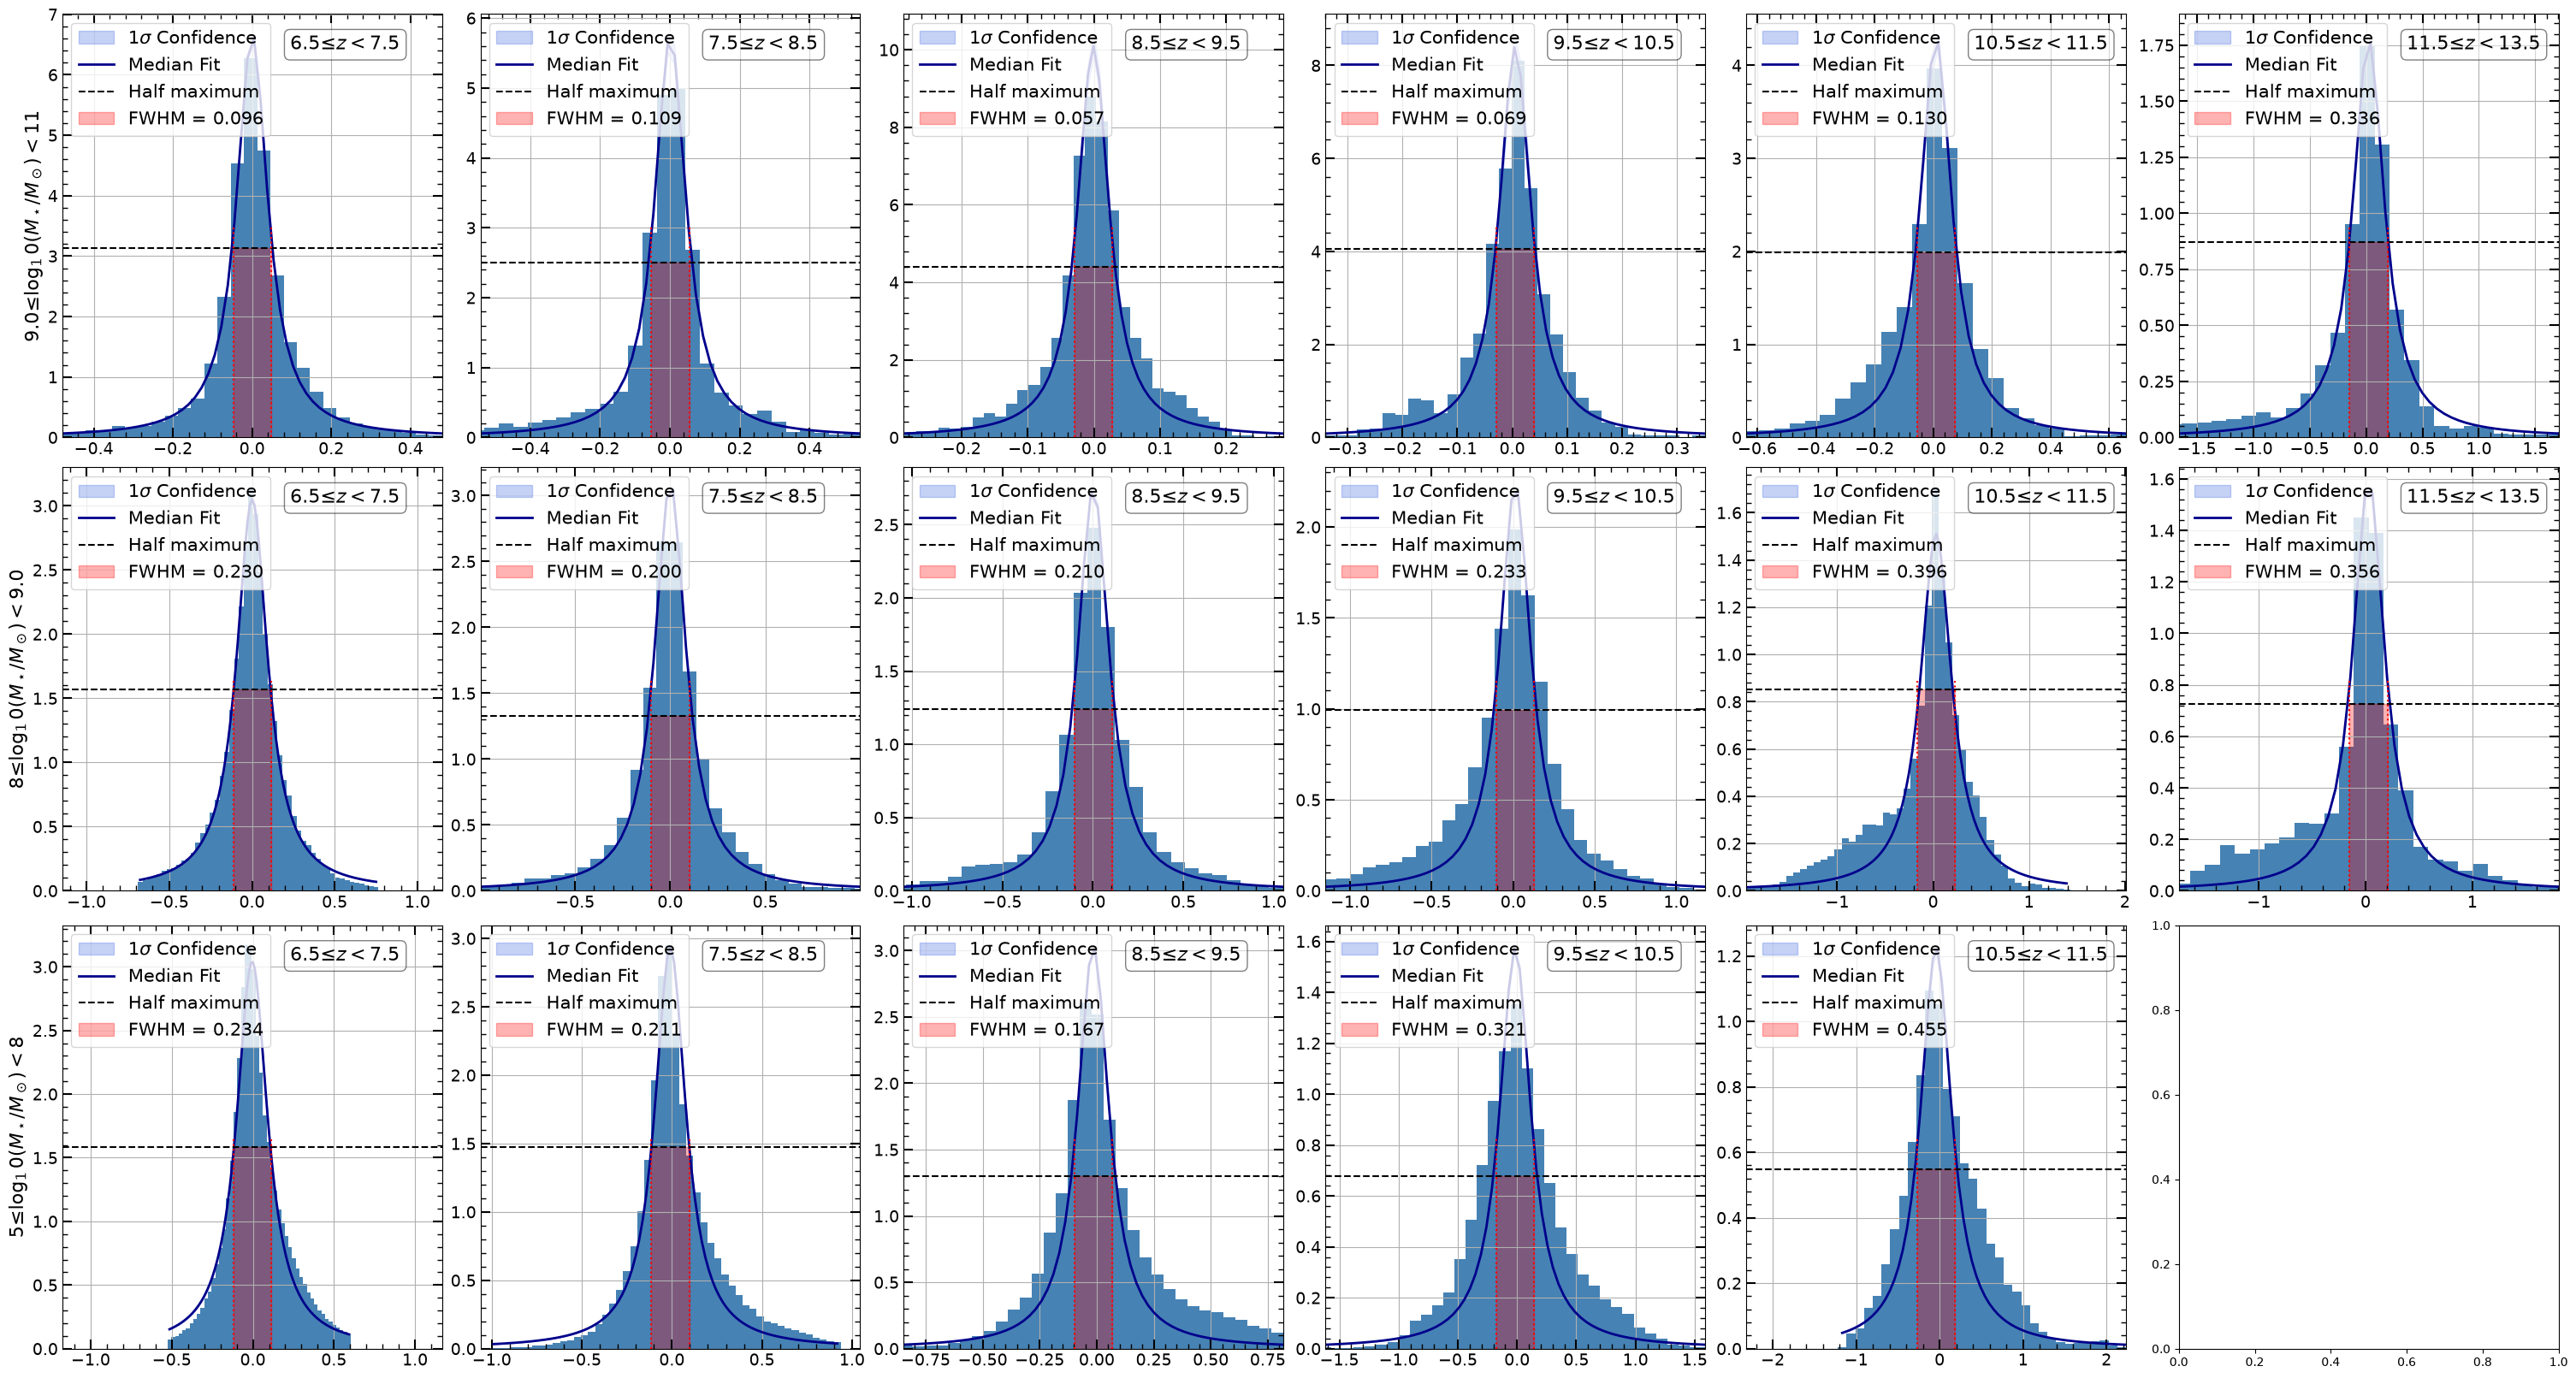

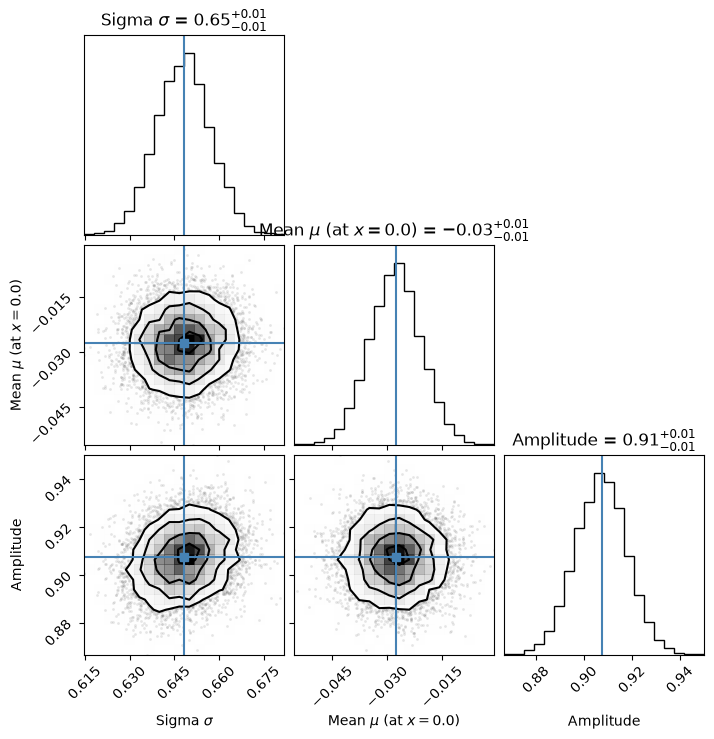

Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Lorentzian_fit_results/results_table_m<8_z=12.5.h5
Median sigma: 0.648, mean: -0.028, amplitude: 0.907


In [115]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0], refit=False)